In [1]:

from pathlib import Path
import random
import numpy as np
import torch
import timm

# 1. Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Project paths
DATA_DIR = Path.cwd()
SPLIT_FILE = DATA_DIR / "dataset_split.csv"

MODEL_NAME = "tiny_vit_21m_224.in1k"

BASELINE_CHECKPOINT = (
    DATA_DIR
    / "results"
    / "tinyvit_21m"
    / "checkpoints"
    / "tinyvit_21m_best.pth"
)

RESULTS_DIR = (
    DATA_DIR / "results" / "tinyvit_21m_finetune"
)

CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
PLOTS_DIR = RESULTS_DIR / "plots"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# 3. Device
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

assert SPLIT_FILE.exists()
assert BASELINE_CHECKPOINT.exists()

# 4. Recreate TinyViT-21M architecture
model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=3
)

# 5. Load best head-only checkpoint
checkpoint = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["model_name"] == MODEL_NAME

model.load_state_dict(
    checkpoint["model_state_dict"]
)

baseline_f1 = float(
    checkpoint["val_macro_f1"]
)

print("LOADED BASELINE")
print("-" * 55)

print("Checkpoint epoch:", checkpoint["epoch"])
print(f"Baseline macro-F1: {baseline_f1:.4f}")

# 6. Inspect TinyViT stages
print("\nTINYVIT-21M STAGES")
print("-" * 55)

for i, stage in enumerate(model.stages):

    params = sum(
        p.numel() for p in stage.parameters()
    )

    print(
        f"Stage {i+1}: "
        f"{type(stage).__name__} | "
        f"{params:,} parameters"
    )

# 7. Freeze all parameters
for param in model.parameters():
    param.requires_grad = False

# 8. Unfreeze final stage
for param in model.stages[-1].parameters():
    param.requires_grad = True

# 9. Unfreeze classification layer
for param in model.head.fc.parameters():
    param.requires_grad = True

model = model.to(DEVICE)

# 10. Keep frozen normalization statistics fixed
model.eval()

# IMPORTANT:
# TinyViT caches relative attention biases in eval mode.
# Reactivate attention in the trainable final stage.
for block in model.stages[-1].blocks:
    block.attn.train()

# 11. Parameter verification
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

stage_params = sum(
    p.numel()
    for p in model.stages[-1].parameters()
)

head_params = sum(
    p.numel()
    for p in model.head.fc.parameters()
)

attention_blocks = list(
    model.stages[-1].blocks
)

assert trainable_params == stage_params + head_params
assert total_params == 20_623_299
assert trainable_params == 8_555_367

assert all(
    block.attn.training
    for block in attention_blocks
)

# 12. Print configuration
print("\nFINE-TUNING CONFIGURATION")
print("=" * 55)

print("Device:", DEVICE)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters:    {frozen_params:,}")

print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

print("\nTrainable components:")
print(f"  Final stage: {stage_params:,}")
print(f"  Classification layer: {head_params:,}")

print("\nAttention blocks:", len(attention_blocks))

print(
    "Attention training mode:",
    all(block.attn.training for block in attention_blocks)
)

print("\nResults directory:")
print(RESULTS_DIR)

print("\nTinyViT-21M fine-tuning setup complete!")


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LOADED BASELINE
-------------------------------------------------------
Checkpoint epoch: 6
Baseline macro-F1: 0.9554

TINYVIT-21M STAGES
-------------------------------------------------------
Stage 1: ConvLayer | 157,824 parameters
Stage 2: TinyVitStage | 952,716 parameters
Stage 3: TinyVitStage | 10,913,184 parameters
Stage 4: TinyVitStage | 8,553,636 parameters

FINE-TUNING CONFIGURATION
Device: mps
Total parameters:     20,623,299
Trainable parameters: 8,555,367
Frozen parameters:    12,067,932
Trainable percentage: 41.48%

Trainable components:
  Final stage: 8,553,636
  Classification layer: 1,731

Attention blocks: 2
Attention training mode: True

Results directory:
/Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_finetune

TinyViT-21M fine-tuning setup complete!


In [2]:

import csv
from collections import Counter

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# 1. Class mapping
CLASSES = ["Brittle", "Ductile", "Mixed"]

class_to_idx = {
    "Brittle": 0,
    "Ductile": 1,
    "Mixed": 2
}

assert checkpoint["class_to_idx"] == class_to_idx

# 2. Load the original split manifest
with open(SPLIT_FILE, "r", encoding="utf-8-sig") as f:
    split_records = list(csv.DictReader(f))

train_records = [
    r for r in split_records
    if r["split"] == "train"
]

val_records = [
    r for r in split_records
    if r["split"] == "validation"
]

test_records = [
    r for r in split_records
    if r["split"] == "test"
]

# 3. ImageNet normalization
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# 4. Training preprocessing
train_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# 5. Validation preprocessing
eval_transform = transforms.Compose([
    transforms.Resize(
        (224, 224),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# 6. SEM Dataset
class SEMDataset(Dataset):

    def __init__(self, records, data_dir, transform):
        self.records = records
        self.data_dir = data_dir
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row = self.records[idx]

        image_path = (
            self.data_dir / row["label"] / row["filename"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["label"]]

        return image, label

# 7. Create datasets
train_dataset = SEMDataset(
    train_records, DATA_DIR, train_transform
)

val_dataset = SEMDataset(
    val_records, DATA_DIR, eval_transform
)

# Test dataset intentionally not instantiated.
# The reserved test set remains untouched.

# 8. DataLoaders
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# 9. Class counts
train_counts = Counter(
    r["label"] for r in train_records
)

# 10. Verify dataset sizes
assert len(train_dataset) == 1402
assert len(val_dataset) == 280
assert len(test_records) == 279

# 11. Verify group separation
train_groups = {r["group"] for r in train_records}
val_groups = {r["group"] for r in val_records}
test_groups = {r["group"] for r in test_records}

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# 12. Test one training batch
images, labels = next(iter(train_loader))

assert images.shape == (16, 3, 224, 224)
assert labels.shape == (16,)

print("TINYVIT-21M FINE-TUNING DATASET")
print("=" * 55)

print("\nDATASET SIZES")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Reserved test:", len(test_records))

print("\nTRAINING CLASS DISTRIBUTION")
for cls in CLASSES:
    print(f"  {cls}: {train_counts[cls]}")

print("\nGROUP SEPARATION")
print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Test groups:", len(test_groups))

print("\nBATCHES")
print("Training:", len(train_loader))
print("Validation:", len(val_loader))

print("\nBATCH VERIFICATION")
print("Images:", images.shape)
print("Labels:", labels.shape)

print("\nDataset verification successful!")


TINYVIT-21M FINE-TUNING DATASET

DATASET SIZES
Training: 1402
Validation: 280
Reserved test: 279

TRAINING CLASS DISTRIBUTION
  Brittle: 589
  Ductile: 711
  Mixed: 102

GROUP SEPARATION
Training groups: 147
Validation groups: 28
Test groups: 31

BATCHES
Training: 88
Validation: 18

BATCH VERIFICATION
Images: torch.Size([16, 3, 224, 224])
Labels: torch.Size([16])

Dataset verification successful!


In [3]:

import torch.nn as nn

# 1. Calculate class weights
num_samples = len(train_records)
num_classes = len(CLASSES)

class_weights = torch.tensor(
    [
        num_samples / (num_classes * train_counts[cls])
        for cls in CLASSES
    ],
    dtype=torch.float32,
    device=DEVICE
)

# 2. Weighted cross-entropy loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# 3. Differential learning rates
STAGE_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-4

# 4. Optimizer
optimizer = torch.optim.AdamW(
    [
        {
            "params": model.stages[-1].parameters(),
            "lr": STAGE_LR
        },
        {
            "params": model.head.fc.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

# 5. Verify optimized parameters
optimized_params = sum(
    p.numel()
    for group in optimizer.param_groups
    for p in group["params"]
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

assert optimized_params == trainable_params
assert trainable_params == 8_555_367

# 6. Configure attention layers
# Keep frozen BatchNorm statistics unchanged.
model.eval()

# Reactivate attention layers in final stage.
for block in model.stages[-1].blocks:
    block.attn.train()

attention_blocks = [
    block.attn
    for block in model.stages[-1].blocks
]

assert len(attention_blocks) == 2
assert all(attn.training for attn in attention_blocks)

# 7. Diagnostic forward/backward pass
# No optimizer.step(), so model weights stay unchanged.
optimizer.zero_grad(set_to_none=True)

images, labels = next(iter(train_loader))

images = images.to(DEVICE)
labels = labels.to(DEVICE)

outputs = model(images)
loss = criterion(outputs, labels)

loss.backward()

# 8. Verify attention gradients
first_attention = attention_blocks[0]

bias_grad = first_attention.attention_biases.grad
qkv_grad = first_attention.qkv.weight.grad

assert bias_grad is not None, (
    "Attention bias gradient is missing"
)

assert qkv_grad is not None, (
    "Attention QKV gradient is missing"
)

assert torch.isfinite(bias_grad).all().item()
assert torch.isfinite(qkv_grad).all().item()

bias_grad_norm = bias_grad.norm().item()
qkv_grad_norm = qkv_grad.norm().item()

# 9. Verify frozen parameters have no gradients
frozen_grad_count = sum(
    p.grad is not None
    for p in model.parameters()
    if not p.requires_grad
)

assert frozen_grad_count == 0

# Clear diagnostic gradients
optimizer.zero_grad(set_to_none=True)

# 10. Training configuration
MAX_EPOCHS = 10
PATIENCE = 4

checkpoint_path = (
    CHECKPOINT_DIR / "tinyvit_21m_finetuned_best.pth"
)

# 11. Print results
print("TINYVIT-21M FINE-TUNING CONFIGURATION")
print("=" * 60)

print("\nCLASS WEIGHTS")
for cls, weight in zip(CLASSES, class_weights):
    print(f"  {cls}: {weight.item():.4f}")

print("\nOPTIMIZER")
print("Type:", optimizer.__class__.__name__)
print("Final stage learning rate:", STAGE_LR)
print("Classification learning rate:", HEAD_LR)
print("Weight decay:", WEIGHT_DECAY)

print("\nPARAMETERS")
print(f"Total:     {total_params:,}")
print(f"Trainable: {trainable_params:,}")
print(f"Frozen:    {frozen_params:,}")

print("\nGRADIENT VERIFICATION")
print(f"Diagnostic loss: {loss.item():.4f}")
print(f"Attention bias gradient norm: {bias_grad_norm:.6f}")
print(f"Attention QKV gradient norm:  {qkv_grad_norm:.6f}")
print("Frozen parameters with gradients:", frozen_grad_count)

print("\nTRAINING PLAN")
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Gradient clipping max norm: 1.0")
print("Selection metric: Validation macro-F1")

print("\nCheckpoint destination:")
print(checkpoint_path)

print("\nGradient verification successful!")
print("Model weights unchanged by diagnostic.")
print("Ready for fine-tuning!")


TINYVIT-21M FINE-TUNING CONFIGURATION

CLASS WEIGHTS
  Brittle: 0.7934
  Ductile: 0.6573
  Mixed: 4.5817

OPTIMIZER
Type: AdamW
Final stage learning rate: 1e-05
Classification learning rate: 0.0001
Weight decay: 0.0001

PARAMETERS
Total:     20,623,299
Trainable: 8,555,367
Frozen:    12,067,932

GRADIENT VERIFICATION
Diagnostic loss: 0.1480
Attention bias gradient norm: 0.009964
Attention QKV gradient norm:  0.767002
Frozen parameters with gradients: 0

TRAINING PLAN
Maximum epochs: 10
Early stopping patience: 4
Gradient clipping max norm: 1.0
Selection metric: Validation macro-F1

Checkpoint destination:
/Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_finetune/checkpoints/tinyvit_21m_finetuned_best.pth

Gradient verification successful!
Model weights unchanged by diagnostic.
Ready for fine-tuning!


In [5]:

import random
import time
import numpy as np
import torch
import timm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

# =====================================================
# 1. RESTART CONFIGURATION
# =====================================================

RUN_SEED = 43
MAX_EPOCHS = 30
PATIENCE = 4

STAGE_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-4

random.seed(RUN_SEED)
np.random.seed(RUN_SEED)
torch.manual_seed(RUN_SEED)

# =====================================================
# 2. RELOAD ORIGINAL HEAD-ONLY CHECKPOINT
# =====================================================

baseline_checkpoint = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

assert baseline_checkpoint["model_name"] == MODEL_NAME
assert baseline_checkpoint["class_to_idx"] == class_to_idx

baseline_f1 = float(
    baseline_checkpoint["val_macro_f1"]
)

# Fresh architecture, fresh model parameters
model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=3
)

model.load_state_dict(
    baseline_checkpoint["model_state_dict"]
)

# Freeze everything
for p in model.parameters():
    p.requires_grad = False

# Unfreeze final stage
for p in model.stages[-1].parameters():
    p.requires_grad = True

# Unfreeze classification layer
for p in model.head.fc.parameters():
    p.requires_grad = True

model = model.to(DEVICE)

# =====================================================
# 3. FRESH OPTIMIZER
# =====================================================

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.stages[-1].parameters(),
            "lr": STAGE_LR
        },
        {
            "params": model.head.fc.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

# Reuse weighted cross-entropy from Cell 3
# and verify all parameters
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

assert trainable_params == 8_555_367

# =====================================================
# 4. TRACKING AND EARLY STOPPING
# =====================================================

history_ft = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "val_mixed_f1": [],
    "val_mixed_recall": [],
    "epoch_time": []
}

best_f1 = baseline_f1
best_epoch = 0

# NEW LOGIC
has_new_best = False
epochs_without_improvement = 0

# =====================================================
# 5. CHECKPOINT HELPER
# =====================================================

def save_checkpoint(epoch, macro_f1):

    torch.save(
        {
            "model_state_dict": {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            },
            "epoch": epoch,
            "val_macro_f1": float(macro_f1),
            "model_name": MODEL_NAME,
            "class_to_idx": class_to_idx,
            "experiment": "final_stage_finetuning",
            "run_seed": RUN_SEED
        },
        checkpoint_path
    )

# Preserve head-only baseline as fallback
save_checkpoint(
    epoch=0,
    macro_f1=baseline_f1
)

print("RESTARTING TINYVIT-21M FINE-TUNING")
print("=" * 85)

print("Starting checkpoint epoch:",
      baseline_checkpoint["epoch"])

print(f"Baseline Macro-F1: {baseline_f1:.4f}")
print("Run seed:", RUN_SEED)
print("Maximum epochs:", MAX_EPOCHS)

print(
    "Early stopping:",
    f"{PATIENCE} consecutive non-improving "
    "epochs AFTER first new best"
)

print()

# =====================================================
# 6. TRAINING LOOP
# =====================================================

for epoch in range(MAX_EPOCHS):

    if DEVICE.type == "mps":
        torch.mps.synchronize()

    start_time = time.perf_counter()

    # Keep pretrained normalization fixed
    model.eval()

    # TinyViT-specific attention bias handling
    for block in model.stages[-1].blocks:
        block.attn.train()

    assert all(
        block.attn.training
        for block in model.stages[-1].blocks
    )

    train_loss_total = 0.0
    train_samples = 0

    # ------------------------------
    # TRAINING
    # ------------------------------

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            (
                p for p in model.parameters()
                if p.requires_grad
            ),
            max_norm=1.0
        )

        optimizer.step()

        train_loss_total += (
            loss.item() * labels.size(0)
        )

        train_samples += labels.size(0)

    train_loss = train_loss_total / train_samples

    # ------------------------------
    # VALIDATION
    # ------------------------------

    model.eval()

    val_loss_total = 0.0
    val_samples = 0

    all_labels = []
    all_predictions = []

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += (
                loss.item() * labels.size(0)
            )

            val_samples += labels.size(0)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(
                labels.cpu().tolist()
            )

            all_predictions.extend(
                predictions.cpu().tolist()
            )

    val_loss = val_loss_total / val_samples

    # ------------------------------
    # METRICS
    # ------------------------------

    val_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    val_mixed_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    val_mixed_recall = recall_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    if DEVICE.type == "mps":
        torch.mps.synchronize()

    elapsed = time.perf_counter() - start_time

    # ------------------------------
    # RECORD HISTORY
    # ------------------------------

    history_ft["train_loss"].append(train_loss)
    history_ft["val_loss"].append(val_loss)
    history_ft["val_accuracy"].append(val_accuracy)
    history_ft["val_macro_f1"].append(val_macro_f1)
    history_ft["val_mixed_f1"].append(val_mixed_f1)
    history_ft["val_mixed_recall"].append(
        val_mixed_recall
    )
    history_ft["epoch_time"].append(elapsed)

    # =================================================
    # 7. NEW EARLY STOPPING LOGIC
    # =================================================

    if val_macro_f1 > best_f1 + 1e-6:

        # First or subsequent new best
        best_f1 = val_macro_f1
        best_epoch = epoch + 1

        save_checkpoint(
            epoch=best_epoch,
            macro_f1=best_f1
        )

        # Activate early stopping only now
        has_new_best = True
        epochs_without_improvement = 0

        status = "NEW BEST"

    elif not has_new_best:

        # We haven't beaten the baseline yet.
        # Do not count unsuccessful epochs.
        status = "Searching for first improvement"

    else:

        # Only count after first new best
        epochs_without_improvement += 1

        status = (
            f"No improvement "
            f"({epochs_without_improvement}/{PATIENCE})"
        )

    # ------------------------------
    # PRINT PROGRESS
    # ------------------------------

    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.3f} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"Mixed F1: {val_mixed_f1:.3f} | "
        f"Mixed Recall: {val_mixed_recall:.3f} | "
        f"Time: {elapsed:.1f}s | "
        f"{status}",
        flush=True
    )

    # Stop ONLY after a new best has occurred
    if (
        has_new_best
        and epochs_without_improvement >= PATIENCE
    ):
        print(
            "\nEarly stopping triggered: "
            "4 epochs without improvement "
            "AFTER a new best."
        )
        break

# =====================================================
# 8. RESTORE BEST CHECKPOINT
# =====================================================

best_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# =====================================================
# 9. FINAL SUMMARY
# =====================================================

print("\nFINE-TUNING COMPLETED")
print("=" * 65)

print("First improvement achieved:", has_new_best)
print("Best fine-tuning epoch:", best_epoch)

print(
    f"TinyViT-21M baseline Macro-F1: "
    f"{baseline_f1:.4f}"
)

print(
    f"TinyViT-21M best Macro-F1:     "
    f"{best_f1:.4f}"
)

print(
    f"Improvement:                  "
    f"{best_f1 - baseline_f1:+.4f}"
)

print(
    "Total epochs completed:",
    len(history_ft["train_loss"])
)

print(
    "Average epoch time:",
    f"{np.mean(history_ft['epoch_time']):.1f}s"
)

print("\nCheckpoint saved:")
print(checkpoint_path)

print("\nBest checkpoint restored successfully!")


RESTARTING TINYVIT-21M FINE-TUNING
Starting checkpoint epoch: 6
Baseline Macro-F1: 0.9554
Run seed: 43
Maximum epochs: 30
Early stopping: 4 consecutive non-improving epochs AFTER first new best

Epoch 01/30 | Train Loss: 0.1970 | Val Loss: 0.0529 | Accuracy: 0.989 | Macro-F1: 0.9732 | Mixed F1: 0.930 | Mixed Recall: 0.952 | Time: 14.6s | NEW BEST
Epoch 02/30 | Train Loss: 0.1691 | Val Loss: 0.0555 | Accuracy: 0.975 | Macro-F1: 0.9396 | Mixed F1: 0.844 | Mixed Recall: 0.905 | Time: 14.4s | No improvement (1/4)
Epoch 03/30 | Train Loss: 0.2061 | Val Loss: 0.0534 | Accuracy: 0.993 | Macro-F1: 0.9810 | Mixed F1: 0.950 | Mixed Recall: 0.905 | Time: 14.4s | NEW BEST
Epoch 04/30 | Train Loss: 0.1677 | Val Loss: 0.0771 | Accuracy: 0.968 | Macro-F1: 0.9279 | Mixed F1: 0.816 | Mixed Recall: 0.952 | Time: 14.8s | No improvement (1/4)
Epoch 05/30 | Train Loss: 0.1545 | Val Loss: 0.0603 | Accuracy: 0.975 | Macro-F1: 0.9315 | Mixed F1: 0.821 | Mixed Recall: 0.762 | Time: 15.0s | No improvement (2/4)


TinyViT-21M Head-Only
              precision    recall  f1-score   support

     Brittle     1.0000    1.0000    1.0000       117
     Ductile     0.9858    0.9789    0.9823       142
       Mixed     0.8636    0.9048    0.8837        21

    accuracy                         0.9821       280
   macro avg     0.9498    0.9612    0.9554       280
weighted avg     0.9826    0.9821    0.9823       280


TinyViT-21M Fine-Tuned
              precision    recall  f1-score   support

     Brittle     1.0000    1.0000    1.0000       117
     Ductile     0.9861    1.0000    0.9930       142
       Mixed     1.0000    0.9048    0.9500        21

    accuracy                         0.9929       280
   macro avg     0.9954    0.9683    0.9810       280
weighted avg     0.9930    0.9929    0.9927       280


HEAD-ONLY CONFUSION MATRIX
[[117   0   0]
 [  0 139   3]
 [  0   2  19]]

FINE-TUNED CONFUSION MATRIX
[[117   0   0]
 [  0 142   0]
 [  0   2  19]]

BEST CHECKPOINT
Epoch: 3
Accuracy: 0.9929

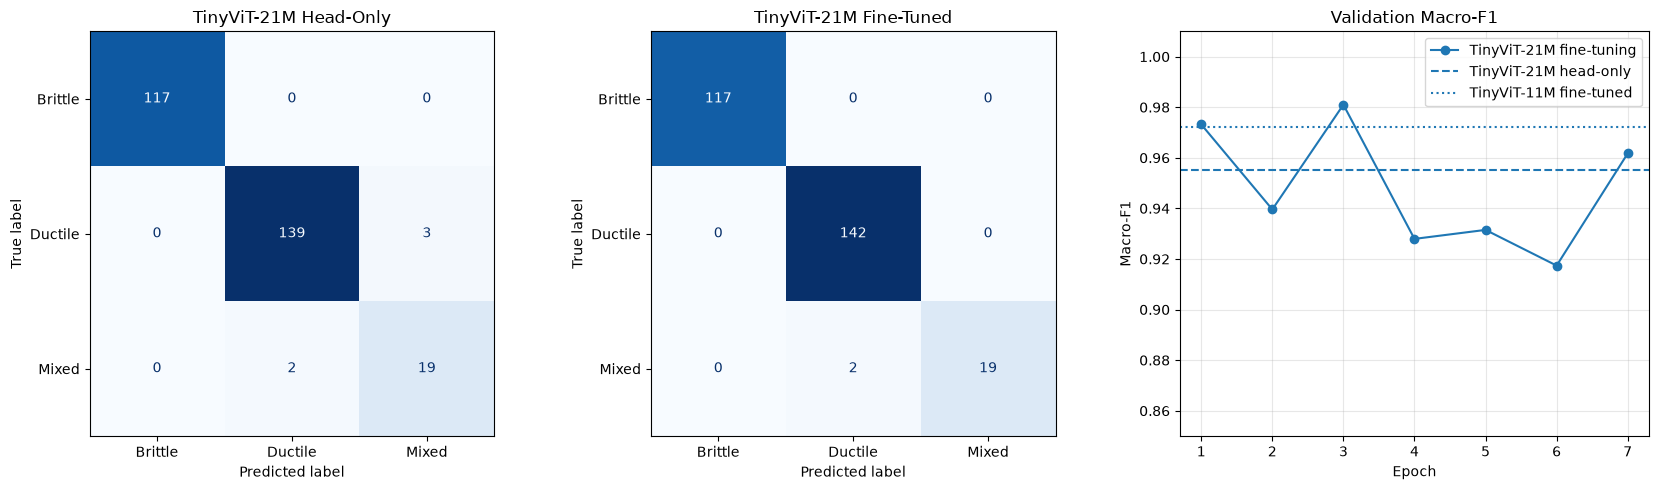


PREDICTION CHANGES
Corrected errors: 3
New errors: 0
Changed but still wrong: 0

CHANGED IMAGES
316L_AR_21_19.png | Actual: Ductile | Before: Mixed | After: Ductile
316L_AR_21_20.png | Actual: Ductile | Before: Mixed | After: Ductile
X65_AR_12_25.png | Actual: Ductile | Before: Mixed | After: Ductile

REMAINING ERRORS
316L_AR_04_15.png | Actual: Mixed | Predicted: Ductile
mX65_H2_26_29.png | Actual: Mixed | Predicted: Ductile

Remaining errors: 2

Plot saved: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_finetune/plots/tinyvit_21m_finetuning_comparison.png

Reserved test set remains untouched.


In [6]:

import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Load original head-only model
baseline_model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=3
)

baseline_model.load_state_dict(
    baseline_checkpoint["model_state_dict"]
)

baseline_model = baseline_model.to(DEVICE)
baseline_model.eval()

# Fine-tuned model was restored to best checkpoint
model.eval()

# 2. Validation prediction helper
def evaluate_model(net, loader):

    actual = []
    predicted = []

    net.eval()

    with torch.inference_mode():

        for images, labels in loader:

            outputs = net(images.to(DEVICE))
            predictions = outputs.argmax(dim=1)

            actual.extend(labels.tolist())
            predicted.extend(predictions.cpu().tolist())

    return actual, predicted

# 3. Evaluate both checkpoints
y_true, baseline_preds = evaluate_model(
    baseline_model, val_loader
)

y_true_ft, finetuned_preds = evaluate_model(
    model, val_loader
)

assert y_true == y_true_ft
assert len(y_true) == 280

assert y_true == [
    class_to_idx[r["label"]]
    for r in val_records
]

# 4. Classification reports
for name, predictions in [
    ("TinyViT-21M Head-Only", baseline_preds),
    ("TinyViT-21M Fine-Tuned", finetuned_preds)
]:

    print("\n" + name)
    print("=" * 60)

    print(classification_report(
        y_true,
        predictions,
        labels=[0, 1, 2],
        target_names=CLASSES,
        digits=4,
        zero_division=0
    ))

# 5. Confusion matrices
cm_before = confusion_matrix(
    y_true, baseline_preds, labels=[0, 1, 2]
)

cm_after = confusion_matrix(
    y_true, finetuned_preds, labels=[0, 1, 2]
)

print("\nHEAD-ONLY CONFUSION MATRIX")
print(cm_before)

print("\nFINE-TUNED CONFUSION MATRIX")
print(cm_after)

# 6. Verify best checkpoint metrics
final_accuracy = accuracy_score(
    y_true, finetuned_preds
)

final_macro_f1 = f1_score(
    y_true,
    finetuned_preds,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

assert abs(final_macro_f1 - best_f1) < 1e-5

print("\nBEST CHECKPOINT")
print("Epoch:", best_epoch)
print(f"Accuracy: {final_accuracy:.4f}")
print(f"Macro-F1: {final_macro_f1:.4f}")

# 7. Generate diagnostics
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

ConfusionMatrixDisplay(
    cm_before,
    display_labels=CLASSES
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[0].set_title("TinyViT-21M Head-Only")

ConfusionMatrixDisplay(
    cm_after,
    display_labels=CLASSES
).plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[1].set_title("TinyViT-21M Fine-Tuned")

epochs = range(
    1,
    len(history_ft["val_macro_f1"]) + 1
)

axes[2].plot(
    epochs,
    history_ft["val_macro_f1"],
    marker="o",
    label="TinyViT-21M fine-tuning"
)

axes[2].axhline(
    baseline_f1,
    linestyle="--",
    label="TinyViT-21M head-only"
)

axes[2].axhline(
    0.9721,
    linestyle=":",
    label="TinyViT-11M fine-tuned"
)

axes[2].set_title("Validation Macro-F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro-F1")
axes[2].set_ylim(0.85, 1.01)
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()

plot_path = (
    PLOTS_DIR / "tinyvit_21m_finetuning_comparison.png"
)

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 8. Compare individual predictions
corrected = []
new_errors = []
changed_still_wrong = []

for i, (actual, before, after) in enumerate(
    zip(y_true, baseline_preds, finetuned_preds)
):

    if before == after:
        continue

    if before != actual and after == actual:
        corrected.append(i)

    elif before == actual and after != actual:
        new_errors.append(i)

    else:
        changed_still_wrong.append(i)

print("\nPREDICTION CHANGES")
print("=" * 60)

print("Corrected errors:", len(corrected))
print("New errors:", len(new_errors))
print("Changed but still wrong:",
      len(changed_still_wrong))

print("\nCHANGED IMAGES")

for i in corrected + new_errors + changed_still_wrong:

    print(
        f"{val_records[i]['filename']} | "
        f"Actual: {CLASSES[y_true[i]]} | "
        f"Before: {CLASSES[baseline_preds[i]]} | "
        f"After: {CLASSES[finetuned_preds[i]]}"
    )

# 9. Remaining fine-tuned errors
remaining_errors = [
    i
    for i, (actual, pred) in enumerate(
        zip(y_true, finetuned_preds)
    )
    if actual != pred
]

print("\nREMAINING ERRORS")
print("=" * 60)

for i in remaining_errors:

    print(
        f"{val_records[i]['filename']} | "
        f"Actual: {CLASSES[y_true[i]]} | "
        f"Predicted: {CLASSES[finetuned_preds[i]]}"
    )

print("\nRemaining errors:", len(remaining_errors))
print("\nPlot saved:", plot_path)
print("\nReserved test set remains untouched.")


In [7]:

import json
from datetime import datetime, timezone

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Calculate exact validation metrics
def metrics_dict(actual, predicted):
    return {
        "accuracy": float(
            accuracy_score(actual, predicted)
        ),
        "macro_f1": float(
            f1_score(
                actual,
                predicted,
                labels=[0, 1, 2],
                average="macro",
                zero_division=0
            )
        ),
        "classification_report": classification_report(
            actual,
            predicted,
            labels=[0, 1, 2],
            target_names=CLASSES,
            output_dict=True,
            zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            actual,
            predicted,
            labels=[0, 1, 2]
        ).tolist()
    }

head_metrics = metrics_dict(y_true, baseline_preds)
fine_metrics = metrics_dict(y_true, finetuned_preds)

assert abs(
    fine_metrics["macro_f1"] - best_f1
) < 1e-5

assert best_checkpoint["epoch"] == 3
assert sum(
    y != p for y, p in zip(y_true, finetuned_preds)
) == 2

# 2. Save prediction-level changes
prediction_changes = []

for i, (actual, before, after) in enumerate(
    zip(y_true, baseline_preds, finetuned_preds)
):
    if before == after:
        continue

    if before != actual and after == actual:
        status = "corrected"
    elif before == actual and after != actual:
        status = "new_error"
    else:
        status = "changed_still_wrong"

    prediction_changes.append({
        "filename": val_records[i]["filename"],
        "actual": CLASSES[actual],
        "before": CLASSES[before],
        "after": CLASSES[after],
        "status": status
    })

remaining_error_details = [
    {
        "filename": val_records[i]["filename"],
        "actual": CLASSES[y_true[i]],
        "predicted": CLASSES[finetuned_preds[i]]
    }
    for i in remaining_errors
]

# 3. Preserve the earlier fine-tuning attempt
# Values transcribed from the first run's output.
first_attempt = {
    "description": "Original fine-tuning attempt",
    "notebook_setup_seed": 42,
    "maximum_epochs": 10,
    "early_stopping_patience": 4,
    "early_stopping_rule":
        "Patience counted immediately from baseline",
    "epochs_completed": 4,
    "best_macro_f1": 0.9554,
    "improved_over_head_only": False,
    "checkpoint_retained": "Head-only baseline",
    "history": {
        "train_loss": [
            0.2254, 0.1817, 0.2020, 0.1308
        ],
        "val_loss": [
            0.0538, 0.0707, 0.0641, 0.0713
        ],
        "val_accuracy": [
            0.975, 0.979, 0.979, 0.975
        ],
        "val_macro_f1": [
            0.9370, 0.9375, 0.9494, 0.9394
        ],
        "val_mixed_f1": [
            0.837, 0.833, 0.870, 0.844
        ],
        "val_mixed_recall": [
            0.857, 0.714, 0.952, 0.905
        ],
        "epoch_time": [
            15.1, 14.4, 14.5, 14.5
        ]
    }
}

# 4. Construct final summary
summary = {
    "experiment": "TinyViT-21M SEM Fracture Classification",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "architecture": {
        "name": MODEL_NAME,
        "type": "Hybrid CNN-Vision Transformer",
        "pretraining": "ImageNet-1K",
        "total_parameters": 20_623_299,
        "head_only_trainable_parameters": 1731,
        "finetuning_trainable_parameters": 8_555_367,
        "input_size": [224, 224]
    },

    "dataset": {
        "split_file": "dataset_split.csv",
        "training_images": len(train_records),
        "validation_images": len(val_records),
        "reserved_test_images": len(test_records),
        "train_groups": len(train_groups),
        "validation_groups": len(val_groups),
        "test_groups": len(test_groups),
        "grouping": "Filename-derived",
        "classes": CLASSES,
        "training_class_counts": dict(train_counts),
        "batch_size": BATCH_SIZE,
        "interpolation": "bilinear",
        "normalization": "ImageNet mean/std",
        "augmentation": [
            "RandomHorizontalFlip(p=0.5)",
            "RandomVerticalFlip(p=0.5)"
        ]
    },

    "head_only": {
        "best_epoch": int(baseline_checkpoint["epoch"]),
        "checkpoint": str(BASELINE_CHECKPOINT),
        **head_metrics
    },

    "finetuning": {
        "initial_checkpoint": str(BASELINE_CHECKPOINT),
        "best_checkpoint": str(checkpoint_path),
        "best_epoch": int(best_checkpoint["epoch"]),
        "run_seed": RUN_SEED,
        "epochs_completed": len(
            history_ft["train_loss"]
        ),
        "maximum_epochs": MAX_EPOCHS,
        "early_stopping_patience": PATIENCE,
        "early_stopping_rule":
            "Activate patience after first improvement "
            "over head-only baseline",
        "trainable_components": [
            "stages.3",
            "head.fc"
        ],
        "stage_learning_rate": STAGE_LR,
        "head_learning_rate": HEAD_LR,
        "weight_decay": WEIGHT_DECAY,
        "optimizer": "AdamW",
        "loss": "Weighted cross-entropy",
        "class_weights": class_weights.cpu().tolist(),
        "gradient_clip_max_norm": 1.0,
        "history": history_ft,
        "metrics": fine_metrics
    },

    "first_finetuning_attempt": first_attempt,

    "comparison": {
        "macro_f1_gain": (
            fine_metrics["macro_f1"]
            - head_metrics["macro_f1"]
        ),
        "accuracy_gain": (
            fine_metrics["accuracy"]
            - head_metrics["accuracy"]
        ),
        "corrected_errors": len(corrected),
        "new_errors": len(new_errors),
        "changed_still_wrong": len(
            changed_still_wrong
        ),
        "prediction_changes": prediction_changes,
        "remaining_errors": remaining_error_details
    },

    "reference_models": {
        "tinyvit_11m_finetuned_macro_f1": 0.9721,
        "resnet18_finetuned_macro_f1": 0.9525
    },

    "limitations": [
        "Validation metrics only.",
        "Reserved test set not evaluated.",
        "Only 21 Mixed validation images.",
        "Filename grouping does not prove specimen independence.",
        "Two fine-tuning attempts used the same validation set.",
        "Results are sensitive to checkpoint selection.",
        "No repeated-seed uncertainty estimate.",
        "No independent ResNet-50 comparison yet."
    ],

    "test_evaluated": False
}

# 5. Save JSON
summary_path = (
    RESULTS_DIR / "experiment_summary.json"
)

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

# 6. Verify saved JSON
with open(summary_path, "r", encoding="utf-8") as f:
    verified = json.load(f)

assert verified["test_evaluated"] is False
assert verified["finetuning"]["best_epoch"] == 3
assert len(
    verified["comparison"]["remaining_errors"]
) == 2

# 7. Print final results
print("TINYVIT-21M EXPERIMENT SAVED")
print("=" * 60)

print(
    f"Head-only Macro-F1: {head_metrics['macro_f1']:.4f}"
)

print(
    f"Fine-tuned Macro-F1: "
    f"{fine_metrics['macro_f1']:.4f}"
)

print(
    f"Improvement: "
    f"{summary['comparison']['macro_f1_gain']:+.4f}"
)

print("\nFine-tuning attempts recorded: 2")
print("Corrected images:", len(corrected))
print("Remaining errors:", len(remaining_errors))

print("\nSummary saved:")
print(summary_path)

print("\nCheckpoint:")
print(checkpoint_path)

print("\nExperiment documentation verified!")


TINYVIT-21M EXPERIMENT SAVED
Head-only Macro-F1: 0.9554
Fine-tuned Macro-F1: 0.9810
Improvement: +0.0257

Fine-tuning attempts recorded: 2
Corrected images: 3
Remaining errors: 2

Summary saved:
/Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_finetune/experiment_summary.json

Checkpoint:
/Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_finetune/checkpoints/tinyvit_21m_finetuned_best.pth

Experiment documentation verified!


In [8]:

import json
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from torch.utils.data import DataLoader

# 1. Load the best saved TinyViT-21M checkpoint
final_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert final_checkpoint["epoch"] == 3

model.load_state_dict(
    final_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# 2. Create the previously unused test dataset
# IMPORTANT: use eval_transform, not train_transform
test_dataset = SEMDataset(
    test_records,
    DATA_DIR,
    eval_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

assert len(test_dataset) == 279

# 3. Evaluate test images
test_true = []
test_pred = []

with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(DEVICE)
        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        test_true.extend(labels.tolist())
        test_pred.extend(predictions.cpu().tolist())

# 4. Calculate metrics
test_accuracy = accuracy_score(
    test_true, test_pred
)

test_macro_f1 = f1_score(
    test_true,
    test_pred,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

test_cm = confusion_matrix(
    test_true,
    test_pred,
    labels=[0, 1, 2]
)

test_report = classification_report(
    test_true,
    test_pred,
    labels=[0, 1, 2],
    target_names=CLASSES,
    digits=4,
    zero_division=0
)

# 5. Print results
print("TINYVIT-21M — FINAL TEST EVALUATION")
print("=" * 60)

print("Test images:", len(test_true))
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro-F1: {test_macro_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(test_report)

print("\nCONFUSION MATRIX")
print(test_cm)

# 6. Save test results
test_results = {
    "model": MODEL_NAME,
    "checkpoint": str(checkpoint_path),
    "test_images": len(test_true),
    "accuracy": float(test_accuracy),
    "macro_f1": float(test_macro_f1),
    "confusion_matrix": test_cm.tolist(),
    "classification_report": classification_report(
        test_true,
        test_pred,
        labels=[0, 1, 2],
        target_names=CLASSES,
        output_dict=True,
        zero_division=0
    )
}

test_results_path = (
    RESULTS_DIR / "test_evaluation.json"
)

with open(test_results_path, "w") as f:
    json.dump(test_results, f, indent=4)

print("\nSaved:", test_results_path)


TINYVIT-21M — FINAL TEST EVALUATION
Test images: 279
Test accuracy: 0.9606
Test macro-F1: 0.8921

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Brittle     0.9746    0.9914    0.9829       116
     Ductile     0.9789    0.9720    0.9754       143
       Mixed     0.7368    0.7000    0.7179        20

    accuracy                         0.9606       279
   macro avg     0.8968    0.8878    0.8921       279
weighted avg     0.9597    0.9606    0.9601       279


CONFUSION MATRIX
[[115   0   1]
 [  0 139   4]
 [  3   3  14]]

Saved: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/tinyvit_21m_finetune/test_evaluation.json


In [9]:

import pandas as pd
from pathlib import Path

# Build prediction-level audit
audit_rows = []

for record, actual, predicted in zip(
    test_records, test_true, test_pred
):
    filename = record["filename"]
    parts = Path(filename).stem.split("_")

    audit_rows.append({
        "filename": filename,
        "group": record["group"],
        "material": parts[0],
        "environment": parts[1] if len(parts) > 1 else "Unknown",
        "actual": CLASSES[actual],
        "predicted": CLASSES[predicted],
        "correct": actual == predicted
    })

audit = pd.DataFrame(audit_rows)

assert len(audit) == 279

errors = audit[~audit["correct"]].copy()

print("TEST SET — ERROR AUDIT")
print("=" * 65)
print(f"Total images: {len(audit)}")
print(f"Correct: {audit['correct'].sum()}")
print(f"Errors: {len(errors)}")

print("\nMISCLASSIFIED IMAGES")
print(
    errors[
        [
            "filename",
            "group",
            "material",
            "environment",
            "actual",
            "predicted"
        ]
    ].to_string(index=False)
)

print("\nACCURACY BY MATERIAL")
by_material = audit.groupby("material").agg(
    images=("correct", "size"),
    correct=("correct", "sum")
)
by_material["accuracy"] = (
    by_material["correct"] /
    by_material["images"]
).round(4)

print(by_material.to_string())

print("\nACCURACY BY ENVIRONMENT")
by_environment = audit.groupby("environment").agg(
    images=("correct", "size"),
    correct=("correct", "sum")
)
by_environment["accuracy"] = (
    by_environment["correct"] /
    by_environment["images"]
).round(4)

print(by_environment.to_string())

# Preserve the prediction audit
audit_path = RESULTS_DIR / "test_prediction_audit.csv"
audit.to_csv(audit_path, index=False)

print("\nSaved:", audit_path)


TEST SET — ERROR AUDIT
Total images: 279
Correct: 268
Errors: 11

MISCLASSIFIED IMAGES
           filename        group material environment  actual predicted
  X65_AIR_10_27.png   X65_AIR_10      X65         AIR Brittle     Mixed
   316L_AR_16_3.png   316L_AR_16     316L          AR Ductile     Mixed
   316L_AR_16_4.png   316L_AR_16     316L          AR Ductile     Mixed
   316L_AR_17_2.png   316L_AR_17     316L          AR Ductile     Mixed
  mX65_AR_02_17.png   mX65_AR_02     mX65          AR Ductile     Mixed
 100Cr6_AR_33_1.png 100Cr6_AR_33   100Cr6          AR   Mixed   Brittle
100Cr6_AR_44_22.png 100Cr6_AR_44   100Cr6          AR   Mixed   Brittle
 100Cr6_AR_62_4.png 100Cr6_AR_62   100Cr6          AR   Mixed   Brittle
  316L_H2_13_10.png   316L_H2_13     316L          H2   Mixed   Ductile
  X65_AIR_10_20.png   X65_AIR_10      X65         AIR   Mixed   Ductile
   X65_H2_28_18.png    X65_H2_28      X65          H2   Mixed   Ductile

ACCURACY BY MATERIAL
          images  correct  